<a href="https://colab.research.google.com/github/Yukiii0517/BASC0017/blob/main/BASC0017_CW2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

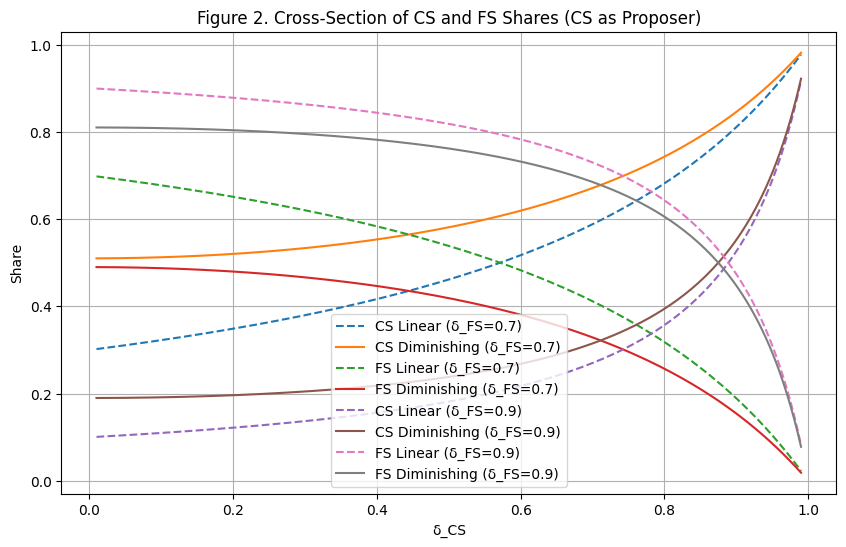

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Vary delta_CS
delta_CS = np.linspace(0.01, 0.99, 200)

# Different fixed delta_FS values
delta_FS_list = [0.7, 0.9]


plt.figure(figsize=(10,6))

for delta_FS in delta_FS_list:

    # --- Shares (Linear case) ---
    cs_share_lin = (1 - delta_FS) / (1 - delta_FS * delta_CS)
    fs_share_lin = (delta_FS * (1 - delta_CS)) / (1 - delta_FS * delta_CS)

    # --- Shares (Diminishing case) ---
    cs_share_sqrt = (1 - delta_FS**2) / (1 - (delta_FS**2) * (delta_CS**2))
    fs_share_sqrt = (delta_FS**2 * (1 - delta_CS**2)) / (1 - (delta_FS**2) * (delta_CS**2))

    # --- Plot CS ---
    plt.plot(delta_CS, cs_share_lin, linestyle='--',
             label=f'CS Linear (δ_FS={delta_FS})')

    plt.plot(delta_CS, cs_share_sqrt,
             label=f'CS Diminishing (δ_FS={delta_FS})')

    # --- Plot FS ---
    plt.plot(delta_CS, fs_share_lin, linestyle='--',
             label=f'FS Linear (δ_FS={delta_FS})')

    plt.plot(delta_CS, fs_share_sqrt,
             label=f'FS Diminishing (δ_FS={delta_FS})')

# Labels
plt.xlabel('δ_CS')
plt.ylabel('Share')
plt.title('Figure 2. Cross-Section of CS and FS Shares (CS as Proposer)')

plt.legend()
plt.grid(True)

plt.show()

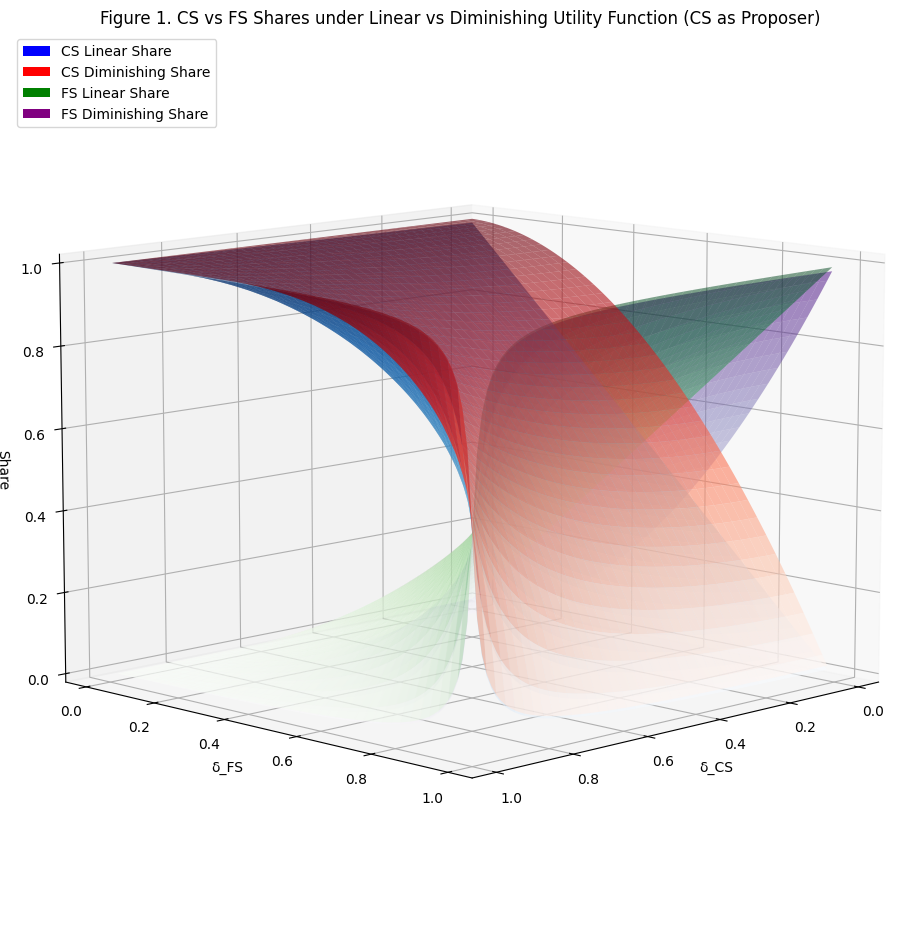

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Grid
delta_CS = np.linspace(0.01, 0.99, 80)
delta_FS = np.linspace(0.01, 0.99, 80)
D_CS, D_FS = np.meshgrid(delta_CS, delta_FS)

# --- Shares ---
cs_share_lin = (1 - D_FS) / (1 - D_FS * D_CS)
fs_share_lin = (D_FS * (1 - D_CS)) / (1 - D_FS * D_CS)

cs_share_sqrt = (1 - D_FS**2) / (1 - (D_FS**2) * (D_CS**2))
fs_share_sqrt = (D_FS**2 * (1 - D_CS**2)) / (1 - (D_FS**2) * (D_CS**2))

# Plot
fig = plt.figure(figsize=(12,10))
ax = fig.add_subplot(111, projection='3d')

ax.view_init(elev=10, azim=45)
plt.subplots_adjust(left=0.05, right=0.95, bottom=0.05, top=0.95)

# Surfaces (NOW SHARES)
ax.plot_surface(D_CS, D_FS, cs_share_lin, alpha=0.6, cmap='Blues')
ax.plot_surface(D_CS, D_FS, cs_share_sqrt, alpha=0.6, cmap='Reds')

ax.plot_surface(D_CS, D_FS, fs_share_lin, alpha=0.5, cmap='Greens')
ax.plot_surface(D_CS, D_FS, fs_share_sqrt, alpha=0.5, cmap='Purples')

# Labels
ax.set_xlabel('δ_CS')
ax.set_ylabel('δ_FS')
ax.set_zlabel('Share')
ax.set_title('Figure 1. CS vs FS Shares under Linear vs Diminishing Utility Function (CS as Proposer)')

# Legend
legend_elements = [
    Patch(facecolor='blue', label='CS Linear Share'),
    Patch(facecolor='red', label='CS Diminishing Share'),
    Patch(facecolor='green', label='FS Linear Share'),
    Patch(facecolor='purple', label='FS Diminishing Share')
]

ax.legend(handles=legend_elements, loc='upper left')

plt.show()